## Assignment no 17

## Forecasting Exchange Rates Using Time Series Analysis

Import Required Libraries

In [2]:
# Install required libraries
# Run this cell only if libraries are missing
%pip install pandas numpy matplotlib seaborn statsmodels scikit-learn openpyxl

Note: you may need to restart the kernel to use updated packages.


In [3]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Time series analysis
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Model diagnostics
from statsmodels.stats.diagnostic import acorr_ljungbox

# Evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Visualization settings
plt.style.use("ggplot")
sns.set_palette("husl")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)

print("All libraries imported successfully!")

All libraries imported successfully!


2. Load the Dataset

In [4]:
# Load dataset
file_path = "exchange_rate.csv"

df = pd.read_csv(file_path)

# Display first five records
display(df.head())

# Display dataset shape
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

,date,Ex_rate
0,01-01-1990 00:00,0.7855
1,02-01-1990 00:00,0.7818
2,03-01-1990 00:00,0.7867
3,04-01-1990 00:00,0.7860
4,05-01-1990 00:00,0.7849


Dataset Shape: (7588, 2)

Column Names:
['date', 'Ex_rate']


3. Convert Date Column and Set Index

In [5]:
# Convert first column into datetime format
date_column = df.columns[0]

df[date_column] = pd.to_datetime(
    df[date_column],
    errors="coerce"
)

# Remove rows containing invalid dates
df = df.dropna(subset=[date_column])

# Sort records chronologically
df = df.sort_values(by=date_column)

# Set date as index
df.set_index(date_column, inplace=True)

# Select second column as the target exchange rate
target_column = df.columns[0]

# Convert target column into numeric format
df[target_column] = pd.to_numeric(
    df[target_column],
    errors="coerce"
)

# Display updated dataset
display(df.head())

print("Target Currency:", target_column)
print("Date Range:", df.index.min(), "to", df.index.max())

,Ex_rate
date,
1990-01-01,0.7855
1990-01-02,0.7500
1990-01-03,0.7471
1990-01-04,0.7587
1990-01-05,0.7852


Target Currency: Ex_rate
Date Range: 1990-01-01 00:00:00 to 2010-12-09 00:00:00


4. Initial Data Exploration

In [6]:
# Dataset information
print("Dataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Check dataset dimensions
print("\nRows:", df.shape[0])
print("Columns:", df.shape[1])

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate dates
print("\nDuplicate Dates:", df.index.duplicated().sum())

# Check duplicate records
print("\nDuplicate Rows:", df.reset_index().duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2998 entries, 1990-01-01 to 2010-12-09
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Ex_rate  2998 non-null   float64
dtypes: float64(1)
memory usage: 46.8 KB

Statistical Summary:


,Ex_rate
count,2998.0000
mean,0.7772
std,0.1372
min,0.4833
25%,0.7034
50%,0.7618
75%,0.8695
max,1.0997



Rows: 2998
Columns: 1

Missing Values:
Ex_rate    0
dtype: int64

Duplicate Dates: 0

Duplicate Rows: 0


5. Handle Duplicate Dates

In [7]:
# Aggregate duplicate dates
df = df.groupby(df.index).mean()

# Sort index chronologically
df = df.sort_index()

print("Duplicate dates after cleaning:",
      df.index.duplicated().sum())

Duplicate dates after cleaning: 0


6. Handle Missing Values

In [8]:
# Check missing values before treatment
print("Missing values before treatment:")
print(df[target_column].isnull().sum())

# Interpolate missing values based on time
df[target_column] = df[target_column].interpolate(
    method="time"
)

# Handle missing values at beginning or end
df[target_column] = df[target_column].ffill().bfill()

# Verify missing values
print("\nMissing values after treatment:")
print(df[target_column].isnull().sum())

Missing values before treatment:
0

Missing values after treatment:
0


7. Visualize Historical Exchange Rates

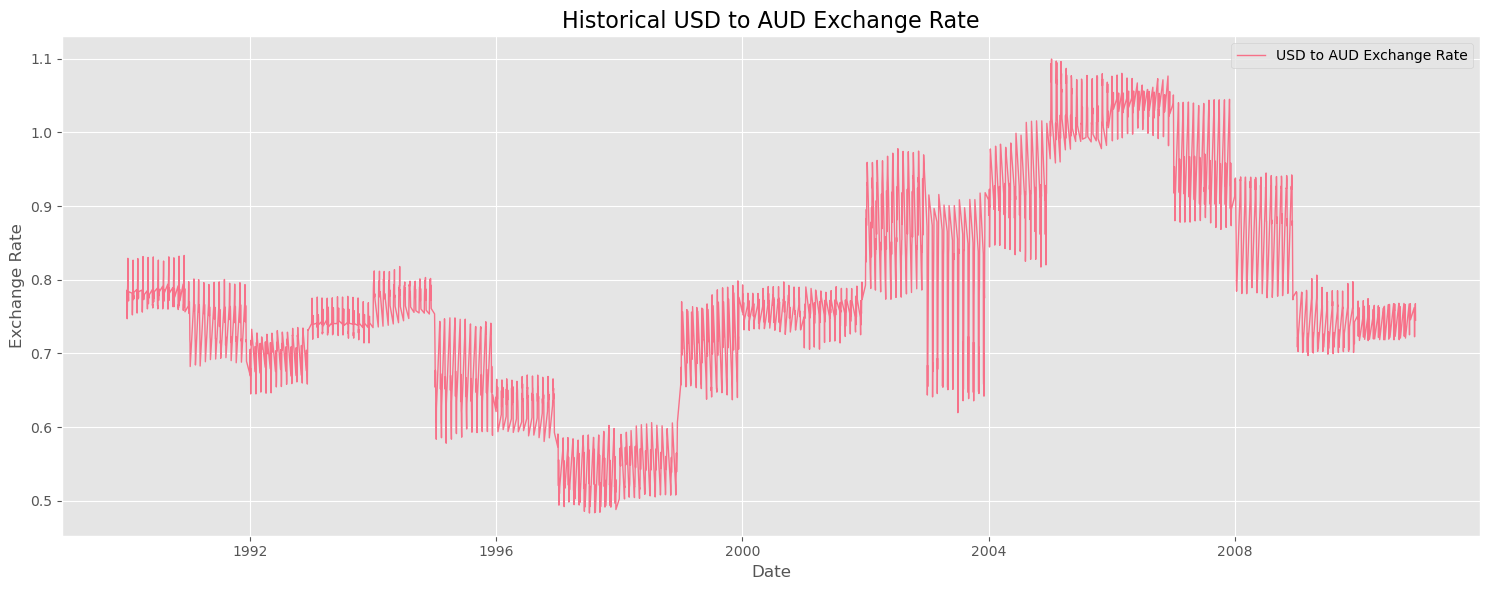

In [9]:
plt.figure(figsize=(15, 6))

plt.plot(
    df.index,
    df[target_column],
    linewidth=1,
    label="USD to AUD Exchange Rate"
)

plt.title(
    "Historical USD to AUD Exchange Rate",
    fontsize=16
)

plt.xlabel("Date")
plt.ylabel("Exchange Rate")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

8. Rolling Mean and Rolling Standard Deviation

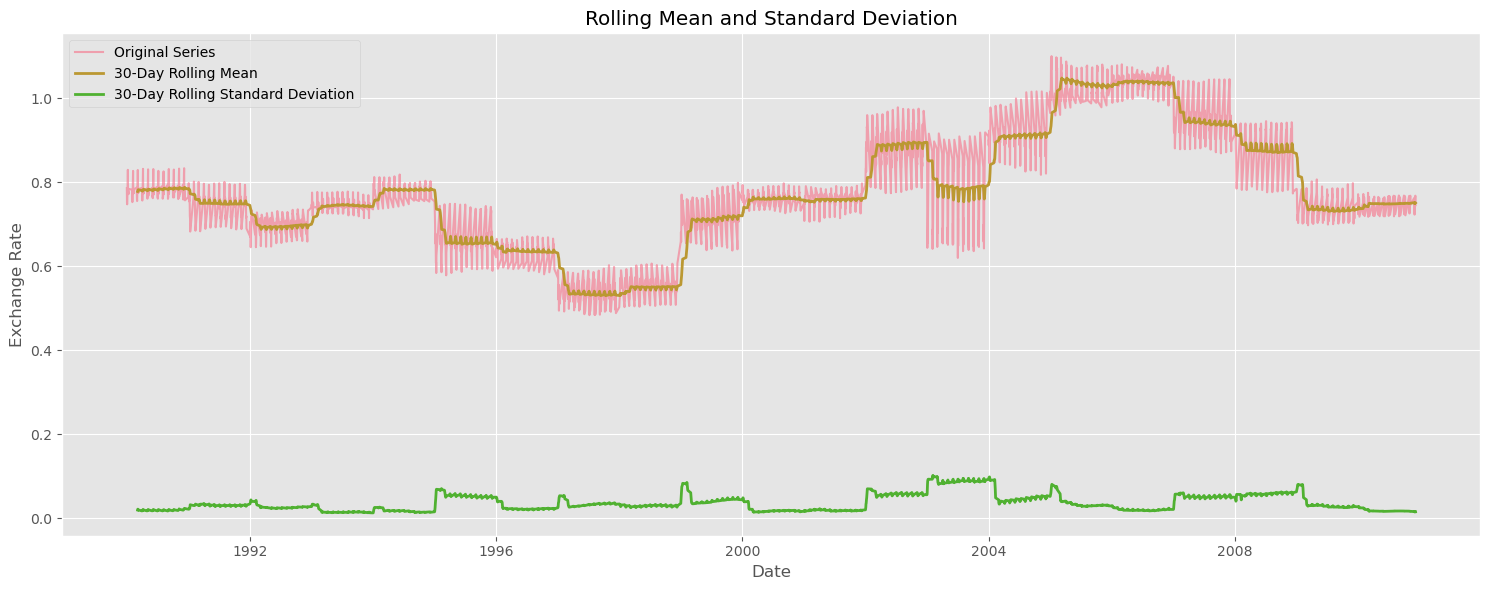

In [10]:
# Calculate rolling statistics
rolling_mean = df[target_column].rolling(window=30).mean()

rolling_std = df[target_column].rolling(window=30).std()

# Plot original series and rolling statistics
plt.figure(figsize=(15, 6))

plt.plot(
    df.index,
    df[target_column],
    label="Original Series",
    alpha=0.6
)

plt.plot(
    df.index,
    rolling_mean,
    label="30-Day Rolling Mean",
    linewidth=2
)

plt.plot(
    df.index,
    rolling_std,
    label="30-Day Rolling Standard Deviation",
    linewidth=2
)

plt.title("Rolling Mean and Standard Deviation")
plt.xlabel("Date")
plt.ylabel("Exchange Rate")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

9. Distribution Analysis

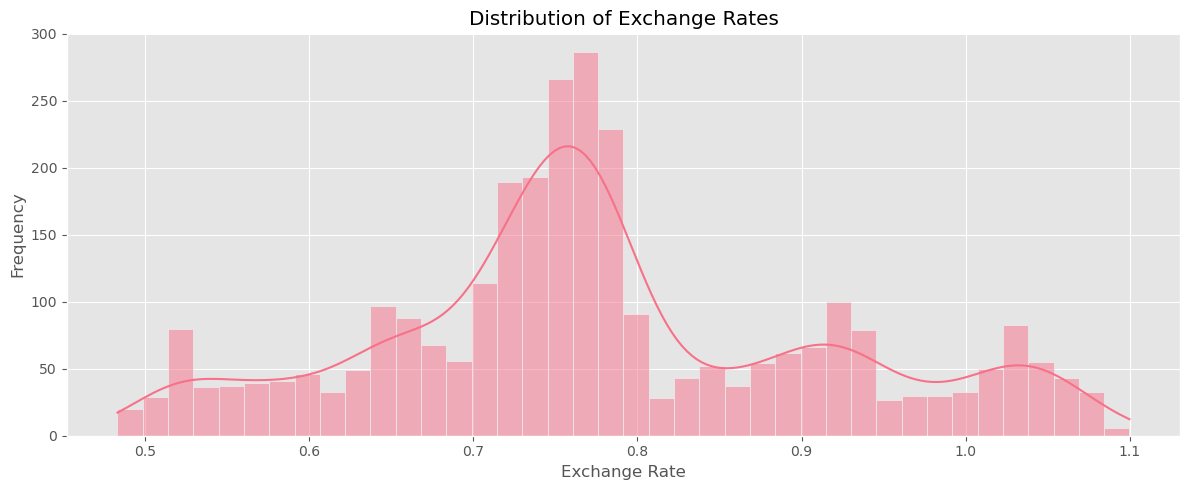

In [11]:
plt.figure(figsize=(12, 5))

sns.histplot(
    df[target_column],
    kde=True,
    bins=40
)

plt.title("Distribution of Exchange Rates")
plt.xlabel("Exchange Rate")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

10. Boxplot for Outlier Detection

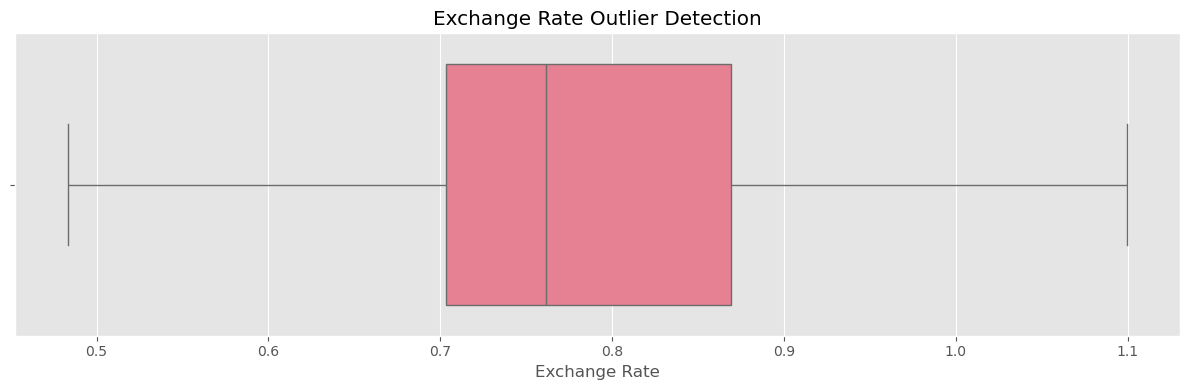

In [12]:
plt.figure(figsize=(12, 4))

sns.boxplot(
    x=df[target_column]
)

plt.title("Exchange Rate Outlier Detection")
plt.xlabel("Exchange Rate")

plt.tight_layout()
plt.show()

11. Stationarity Testing – Augmented Dickey-Fuller Test

In [13]:
# Perform ADF test
adf_result = adfuller(df[target_column].dropna())

print("ADF Statistic:", adf_result[0])
print("P-value:", adf_result[1])

print("\nCritical Values:")
for key, value in adf_result[4].items():
    print(key, ":", value)

# Interpret the result
if adf_result[1] <= 0.05:
    print("\nConclusion: Series is stationary.")
else:
    print("\nConclusion: Series is non-stationary.")

ADF Statistic: -1.5399319076838351
P-value: 0.5136733116580255

Critical Values:
1% : -3.432551464895929
5% : -2.8625126635320393
10% : -2.567287774919901

Conclusion: Series is non-stationary.


12. Differencing to Achieve Stationarity

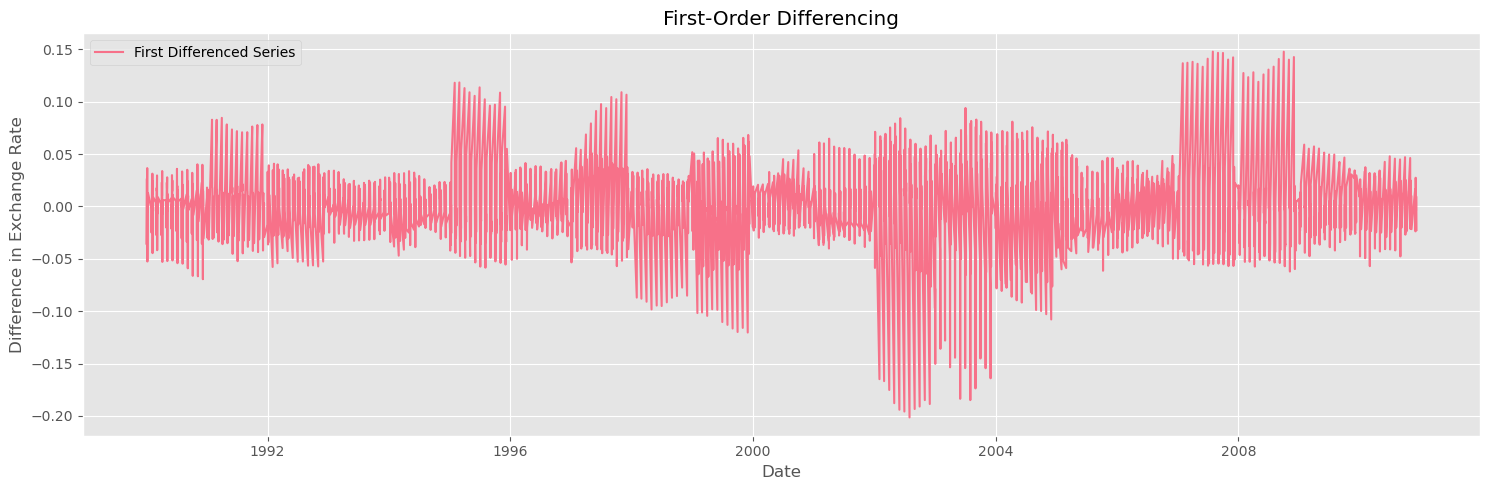

In [14]:
# First-order differencing
diff_series = df[target_column].diff().dropna()

# Plot differenced series
plt.figure(figsize=(15, 5))

plt.plot(
    diff_series.index,
    diff_series,
    label="First Differenced Series"
)

plt.title("First-Order Differencing")
plt.xlabel("Date")
plt.ylabel("Difference in Exchange Rate")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [15]:
# ADF test after differencing
adf_diff = adfuller(diff_series)

print("ADF Statistic:", adf_diff[0])
print("P-value:", adf_diff[1])

if adf_diff[1] <= 0.05:
    print("Differenced series is stationary.")
else:
    print("Differenced series is still non-stationary.")

ADF Statistic: -11.65019397902693
P-value: 2.046104868691766e-21
Differenced series is stationary.


Part 2: Model Building – ARIMA

13. Plot ACF and PACF

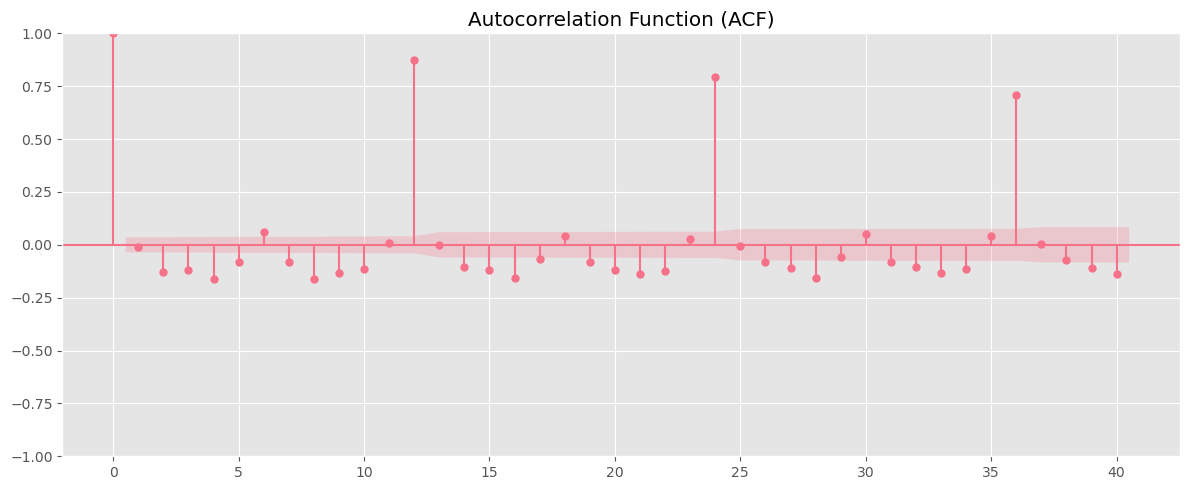

In [16]:
# ACF plot
fig, ax = plt.subplots(figsize=(12, 5))

plot_acf(
    diff_series,
    lags=40,
    ax=ax
)

plt.title("Autocorrelation Function (ACF)")
plt.tight_layout()
plt.show()

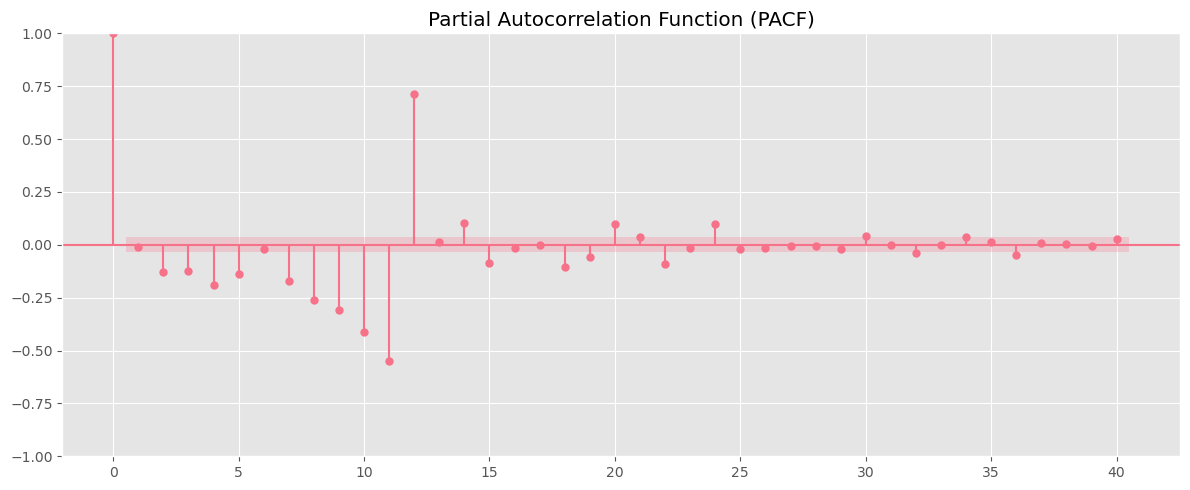

In [17]:
# PACF plot
fig, ax = plt.subplots(figsize=(12, 5))

plot_pacf(
    diff_series,
    lags=40,
    method="ywm",
    ax=ax
)

plt.title("Partial Autocorrelation Function (PACF)")
plt.tight_layout()
plt.show()

14. Split Data into Training and Testing Sets

In [18]:
# Define target time series
series = df[target_column].astype(float)

# Calculate training size
train_size = int(len(series) * 0.80)

# Chronological split
train = series.iloc[:train_size]
test = series.iloc[train_size:]

print("Training Size:", len(train))
print("Testing Size:", len(test))

print("Training Period:",
      train.index.min(), "to", train.index.max())

print("Testing Period:",
      test.index.min(), "to", test.index.max())

Training Size: 2398
Testing Size: 600
Training Period: 1990-01-01 00:00:00 to 2006-08-10 00:00:00
Testing Period: 2006-08-11 00:00:00 to 2010-12-09 00:00:00


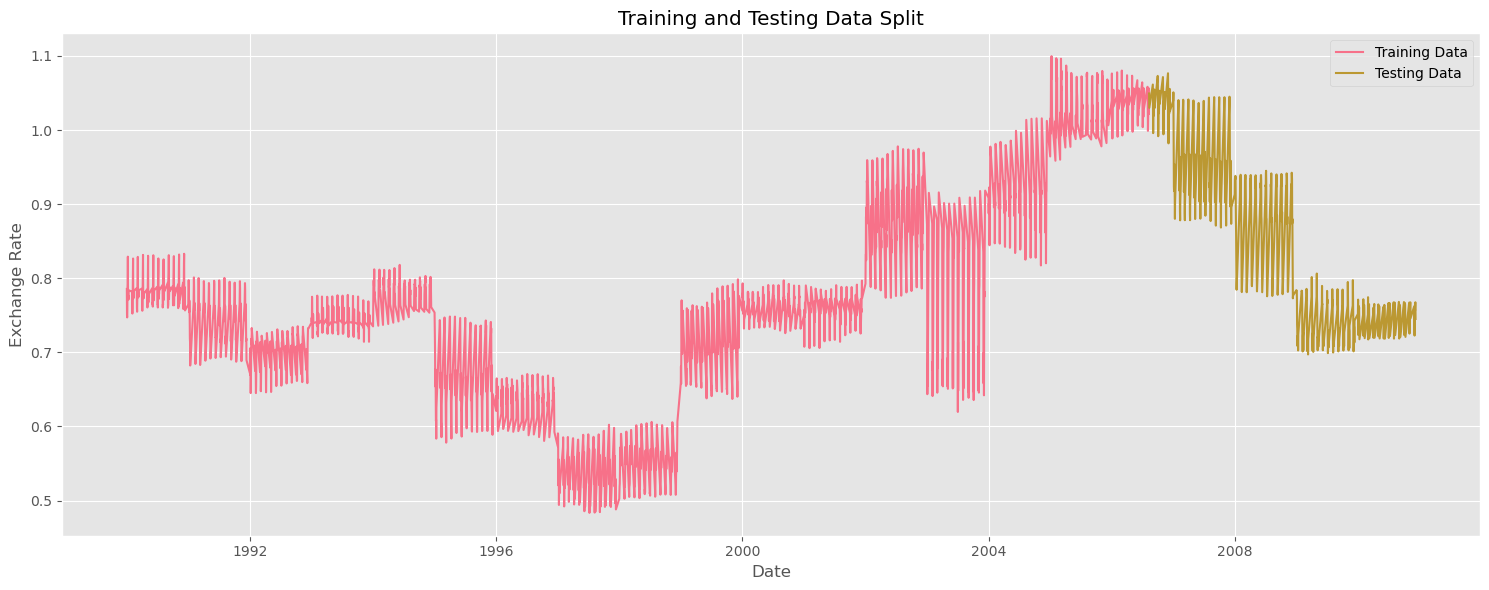

In [19]:
plt.figure(figsize=(15, 6))

plt.plot(
    train.index,
    train,
    label="Training Data"
)

plt.plot(
    test.index,
    test,
    label="Testing Data"
)

plt.title("Training and Testing Data Split")
plt.xlabel("Date")
plt.ylabel("Exchange Rate")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

15. Select Optimal ARIMA Parameters

In [20]:
# Determine differencing order using ADF test
train_adf = adfuller(train.dropna())

if train_adf[1] <= 0.05:
    d = 0
else:
    d = 1

# Check whether first differencing is sufficient
if d == 1:
    first_diff = train.diff().dropna()
    second_adf = adfuller(first_diff)

    if second_adf[1] > 0.05:
        d = 2

print("Selected Differencing Order (d):", d)

Selected Differencing Order (d): 1


In [21]:
# Grid search for ARIMA parameters
import itertools

p_values = range(0, 4)
q_values = range(0, 4)

best_aic = float("inf")
best_order = None
best_model = None

# Test different combinations
for p, q in itertools.product(p_values, q_values):

    try:
        # Fit ARIMA model
        model = ARIMA(
            train,
            order=(p, d, q)
        )

        model_fit = model.fit()

        # Compare AIC
        if model_fit.aic < best_aic:

            best_aic = model_fit.aic
            best_order = (p, d, q)
            best_model = model_fit

    except Exception:
        continue

print("Best ARIMA Order:", best_order)
print("Best AIC:", best_aic)

Best ARIMA Order: (2, 1, 3)
Best AIC: -9686.933597099725


16. Fit the Final ARIMA Model

In [22]:

# Fit final ARIMA model
arima_model = ARIMA(
    train,
    order=best_order
)

arima_fit = arima_model.fit()

# Display model summary
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                Ex_rate   No. Observations:                 2398
Model:                 ARIMA(2, 1, 3)   Log Likelihood                4849.467
Date:                Wed, 04 Nov 2026   AIC                          -9686.934
Time:                        10:43:49   BIC                          -9652.242
Sample:                             0   HQIC                         -9674.312
                               - 2398                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3996      0.025    -15.948      0.000      -0.449      -0.350
ar.L2          0.5660      0.022     25.591      0.000       0.523       0.609
ma.L1          0.2651      0.029      9.281      0.0

17. ARIMA Model Diagnostics

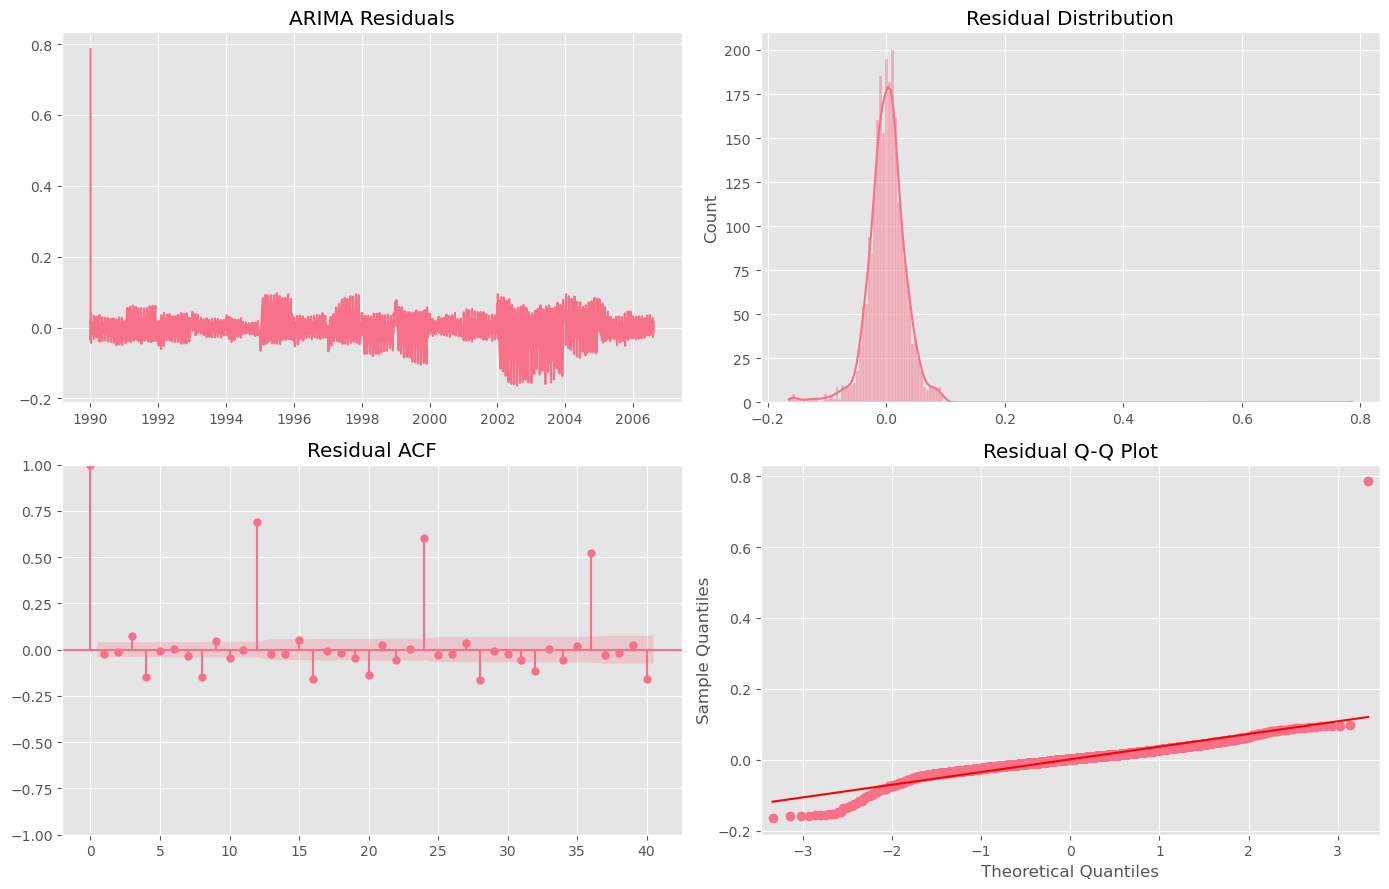

In [23]:
# Extract residuals
arima_residuals = arima_fit.resid

# Plot residuals
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Residual time series
axes[0, 0].plot(arima_residuals)
axes[0, 0].set_title("ARIMA Residuals")

# Residual distribution
sns.histplot(
    arima_residuals,
    kde=True,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Residual Distribution")

# Residual ACF
plot_acf(
    arima_residuals,
    lags=40,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Residual ACF")

# Residual Q-Q plot
from statsmodels.graphics.gofplots import qqplot

qqplot(
    arima_residuals,
    line="s",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Residual Q-Q Plot")

plt.tight_layout()
plt.show()

Ljung-Box Test

In [24]:
# Ljung-Box test
lb_result = acorr_ljungbox(
    arima_residuals,
    lags=[10, 20],
    return_df=True
)

display(lb_result)

if (lb_result["lb_pvalue"] > 0.05).all():
    print("Residuals appear to be white noise.")
else:
    print("Residual autocorrelation may remain.")

,lb_stat,lb_pvalue
10,132.7468,0.0000
20,1394.4599,0.0000


Residual autocorrelation may remain.


18. Forecast Using ARIMA


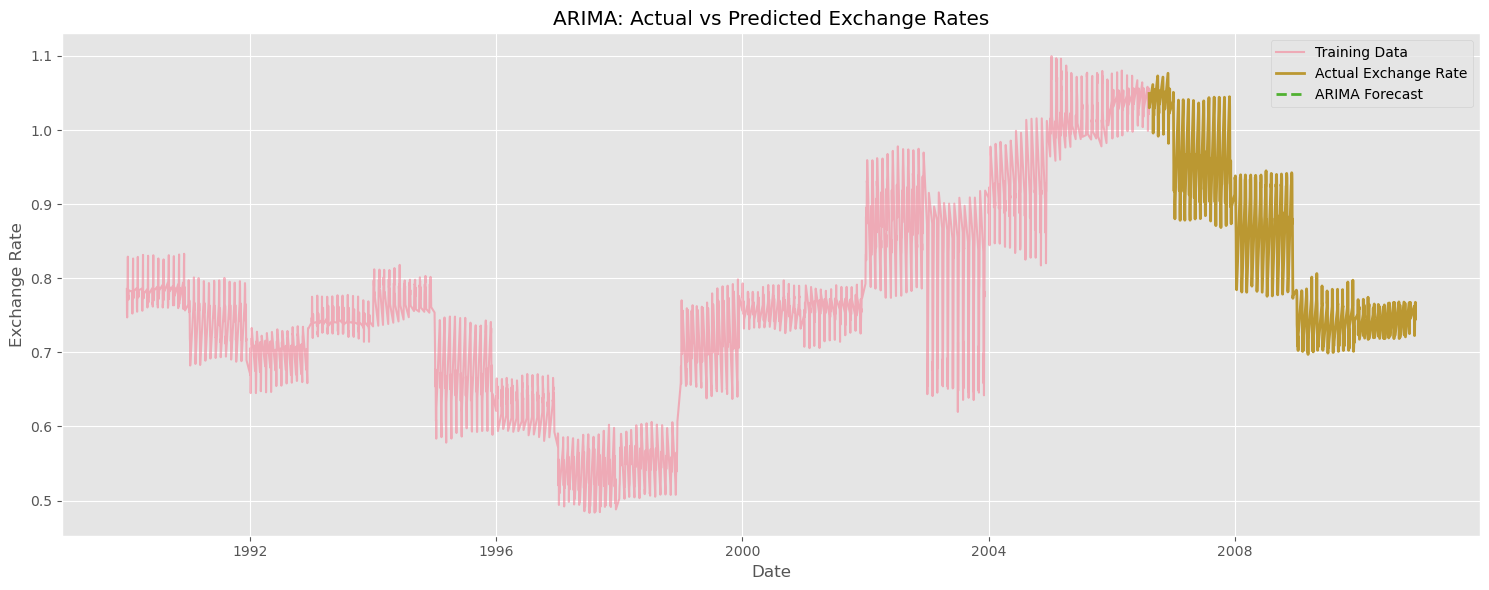

In [25]:
# Forecast testing period
arima_forecast = arima_fit.forecast(
    steps=len(test)
)

# Assign testing dates
arima_forecast = pd.Series(
    arima_forecast,
    index=test.index
)

# Plot actual vs predicted values
plt.figure(figsize=(15, 6))

plt.plot(
    train.index,
    train,
    label="Training Data",
    alpha=0.5
)

plt.plot(
    test.index,
    test,
    label="Actual Exchange Rate",
    linewidth=2
)

plt.plot(
    arima_forecast.index,
    arima_forecast,
    label="ARIMA Forecast",
    linestyle="--",
    linewidth=2
)

plt.title("ARIMA: Actual vs Predicted Exchange Rates")
plt.xlabel("Date")
plt.ylabel("Exchange Rate")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Part 3: Exponential Smoothing Model

19. Understanding Exponential Smoothing

20. Build the Exponential Smoothing Model

In [26]:
# Fit Holt's Exponential Smoothing model
es_model = ExponentialSmoothing(
    train,
    trend="add",
    damped_trend=True,
    seasonal=None,
    initialization_method="estimated"
)

# Train model
es_fit = es_model.fit(
    optimized=True
)

# Display model summary
print(es_fit.summary())

                       ExponentialSmoothing Model Results                       
Dep. Variable:                  Ex_rate   No. Observations:                 2398
Model:             ExponentialSmoothing   SSE                              2.985
Optimized:                         True   AIC                         -16029.874
Trend:                         Additive   BIC                         -16000.962
Seasonal:                          None   AICC                        -16029.827
Seasonal Periods:                  None   Date:                 Wed, 04 Nov 2026
Box-Cox:                          False   Time:                         10:45:14
Box-Cox Coeff.:                    None                                         
                       coeff                 code              optimized      
------------------------------------------------------------------------------
smoothing_level            0.9362772                alpha                 True
smoothing_trend             0.0000

21. Exponential Smoothing Diagnostics

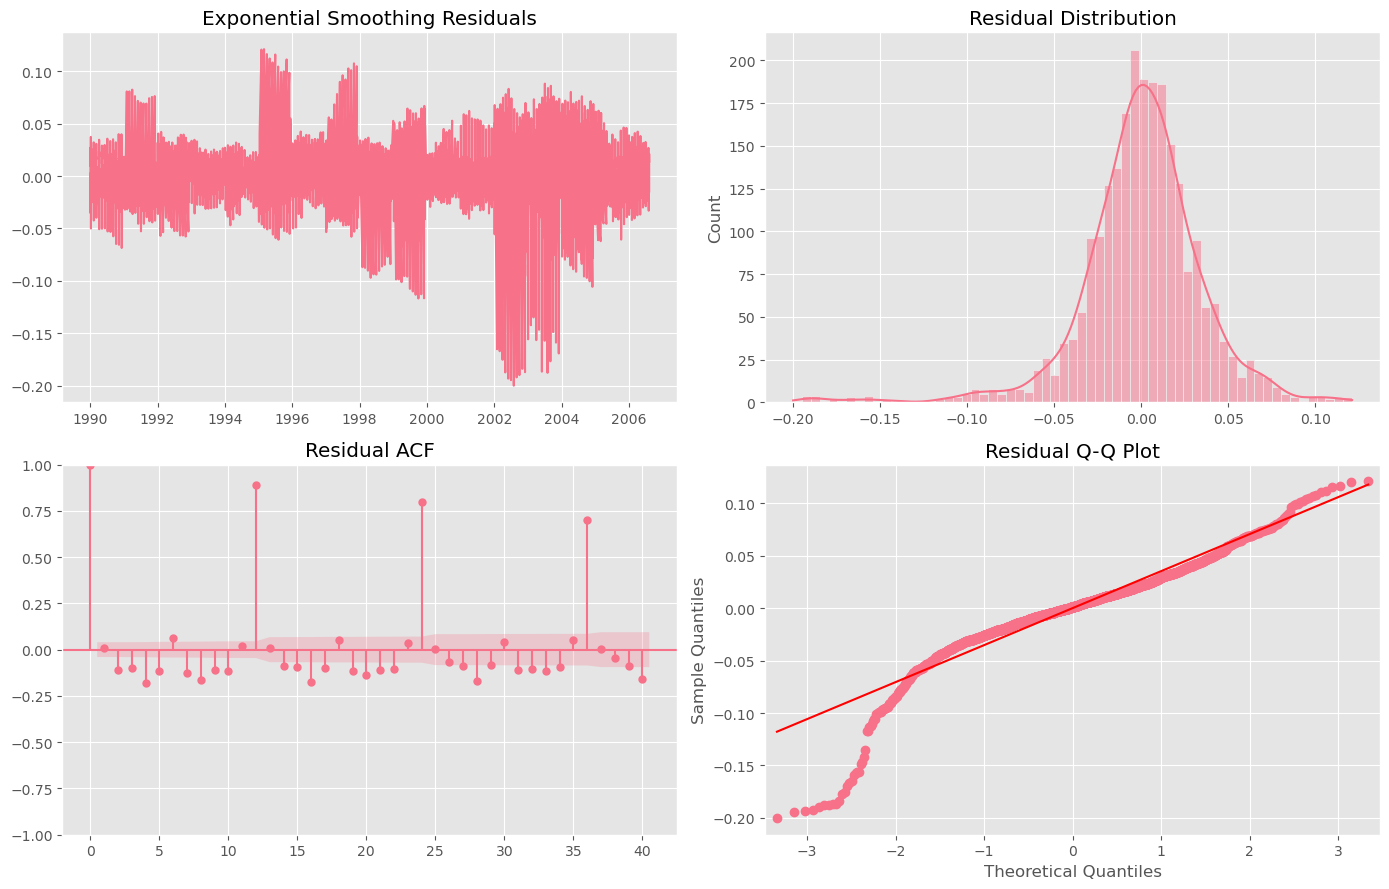

In [27]:
# Extract residuals
es_residuals = es_fit.resid

# Create diagnostic plots
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Residual plot
axes[0, 0].plot(es_residuals)
axes[0, 0].set_title("Exponential Smoothing Residuals")

# Residual distribution
sns.histplot(
    es_residuals,
    kde=True,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Residual Distribution")

# Residual ACF
plot_acf(
    es_residuals,
    lags=40,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Residual ACF")

# Q-Q plot
qqplot(
    es_residuals,
    line="s",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Residual Q-Q Plot")

plt.tight_layout()
plt.show()

22. Ljung-Box Test for Exponential Smoothing

In [28]:
# Check residual autocorrelation
es_lb_result = acorr_ljungbox(
    es_residuals,
    lags=[10, 20],
    return_df=True
)

display(es_lb_result)

if (es_lb_result["lb_pvalue"] > 0.05).all():
    print("Residuals appear to be white noise.")
else:
    print("Residual autocorrelation may remain.")

,lb_stat,lb_pvalue
10,336.3376,0.0000
20,2468.1188,0.0000


Residual autocorrelation may remain.


23. Forecast Using Exponential Smoothing

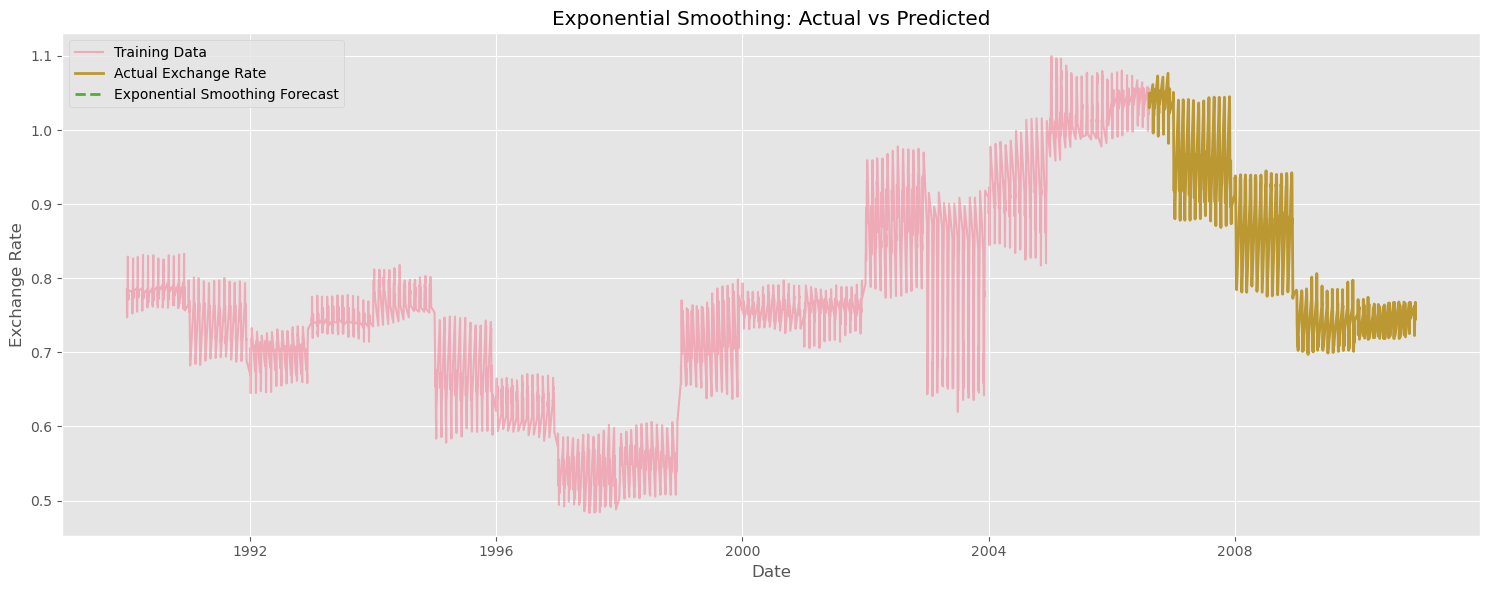

In [29]:
# Forecast testing period
es_forecast = es_fit.forecast(
    steps=len(test)
)

# Assign testing dates
es_forecast = pd.Series(
    es_forecast,
    index=test.index
)

# Visualize forecast
plt.figure(figsize=(15, 6))

plt.plot(
    train.index,
    train,
    label="Training Data",
    alpha=0.5
)

plt.plot(
    test.index,
    test,
    label="Actual Exchange Rate",
    linewidth=2
)

plt.plot(
    es_forecast.index,
    es_forecast,
    label="Exponential Smoothing Forecast",
    linestyle="--",
    linewidth=2
)

plt.title("Exponential Smoothing: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Exchange Rate")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Part 4: Model Evaluation and Comparison

24. Calculate Evaluation Metrics

25. Evaluate ARIMA Model

In [34]:
# ==========================================
# EXPONENTIAL SMOOTHING MODEL EVALUATION
# ==========================================

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Generate fresh forecast
es_forecast = es_fit.forecast(
    steps=len(test)
)

# Convert to arrays
actual_values = test.to_numpy(dtype=float)

forecast_values = np.asarray(
    es_forecast,
    dtype=float
)

# Check valid observations
valid_mask = (
    np.isfinite(actual_values) &
    np.isfinite(forecast_values)
)

actual_clean = actual_values[valid_mask]
forecast_clean = forecast_values[valid_mask]

print("Valid observations:", len(actual_clean))

# Stop if no valid observations
if len(actual_clean) == 0:
    raise ValueError("No valid observations for evaluation.")

# Calculate MAE
es_mae = mean_absolute_error(
    actual_clean,
    forecast_clean
)

# Calculate RMSE
es_rmse = np.sqrt(
    mean_squared_error(
        actual_clean,
        forecast_clean
    )
)

# Calculate MAPE
es_mape = np.mean(
    np.abs(
        (actual_clean - forecast_clean) /
        actual_clean
    )
) * 100

# Display results
print("\nEXPONENTIAL SMOOTHING PERFORMANCE")
print("---------------------------------")
print("MAE:", round(es_mae, 6))
print("RMSE:", round(es_rmse, 6))
print("MAPE:", round(es_mape, 4), "%")

Valid observations: 600

EXPONENTIAL SMOOTHING PERFORMANCE
---------------------------------
MAE: 0.206652
RMSE: 0.233568
MAPE: 26.3853 %


26. Evaluate Exponential Smoothing Model

In [37]:
# Calculate Exponential Smoothing metrics
es_mae = mean_absolute_error(
    test,
    es_forecast
)

es_rmse = np.sqrt(
    mean_squared_error(test, es_forecast)
)

es_mape = np.mean(
    np.abs(
        (test.values - es_forecast.values) /
        np.where(test.values == 0, np.nan, test.values)
    )
) * 100

print("EXPONENTIAL SMOOTHING PERFORMANCE")
print("---------------------------------")
print("MAE:", round(es_mae, 6))
print("RMSE:", round(es_rmse, 6))
print("MAPE:", round(es_mape, 4), "%")

EXPONENTIAL SMOOTHING PERFORMANCE
---------------------------------
MAE: 0.206652
RMSE: 0.233568
MAPE: 26.3853 %


27. Compare Both Models

In [38]:
# Create comparison DataFrame
comparison = pd.DataFrame({
    "Model": [
        "ARIMA",
        "Exponential Smoothing"
    ],

    "MAE": [
        arima_mae,
        es_mae
    ],

    "RMSE": [
        arima_rmse,
        es_rmse
    ],

    "MAPE (%)": [
        arima_mape,
        es_mape
    ]
})

# Display results
display(comparison.round(6))

,Model,MAE,RMSE,MAPE (%)
0,ARIMA,0.1912,0.2191,24.5063
1,Exponential Smoothing,0.2067,0.2336,26.3853


28. Performance Comparison Visualization


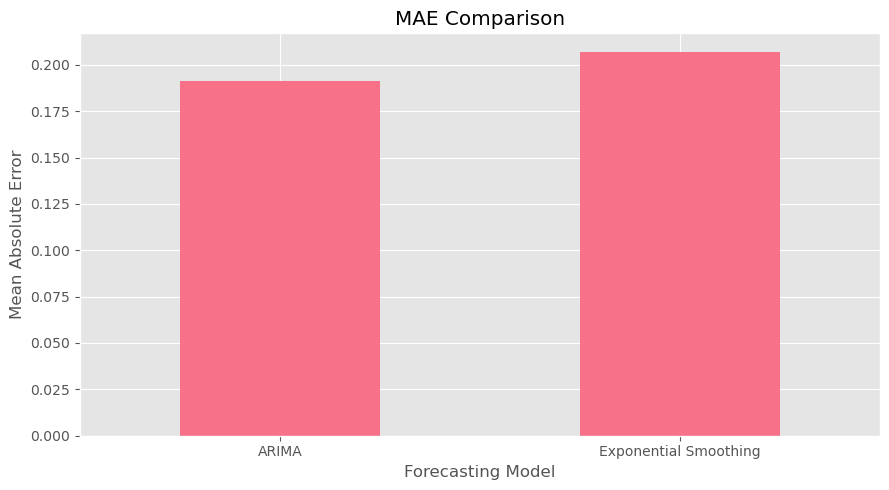

In [39]:
# Convert comparison into plotting format
comparison_plot = comparison.set_index("Model")

# Plot MAE
plt.figure(figsize=(9, 5))

comparison_plot["MAE"].plot(
    kind="bar"
)

plt.title("MAE Comparison")
plt.ylabel("Mean Absolute Error")
plt.xlabel("Forecasting Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

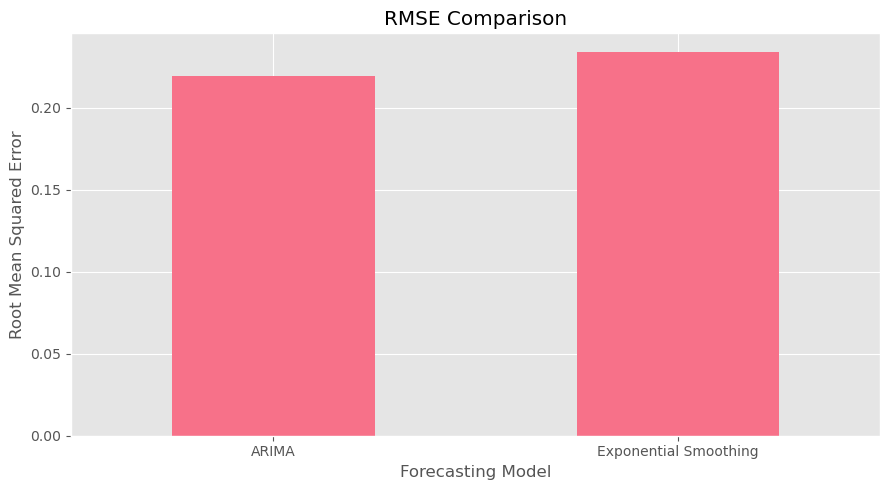

In [40]:
# Plot RMSE
plt.figure(figsize=(9, 5))

comparison_plot["RMSE"].plot(
    kind="bar"
)

plt.title("RMSE Comparison")
plt.ylabel("Root Mean Squared Error")
plt.xlabel("Forecasting Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

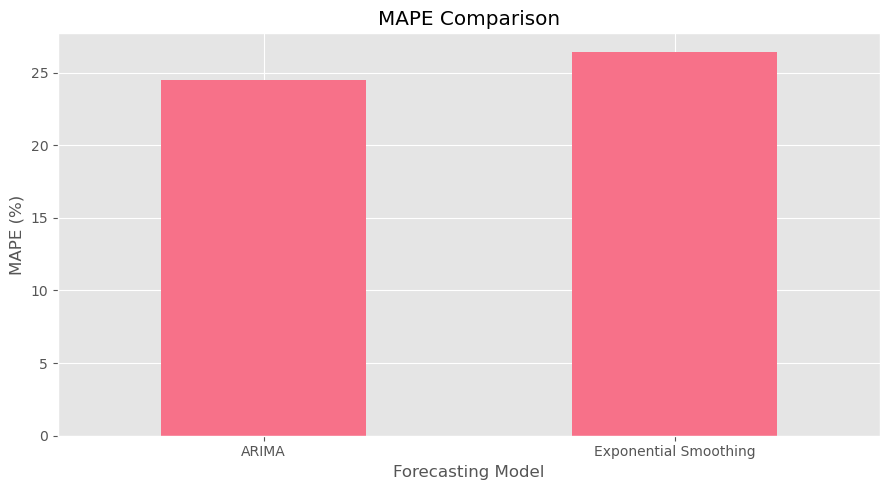

In [41]:
# Plot MAPE
plt.figure(figsize=(9, 5))

comparison_plot["MAPE (%)"].plot(
    kind="bar"
)

plt.title("MAPE Comparison")
plt.ylabel("MAPE (%)")
plt.xlabel("Forecasting Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

29. Actual vs Forecast Comparison

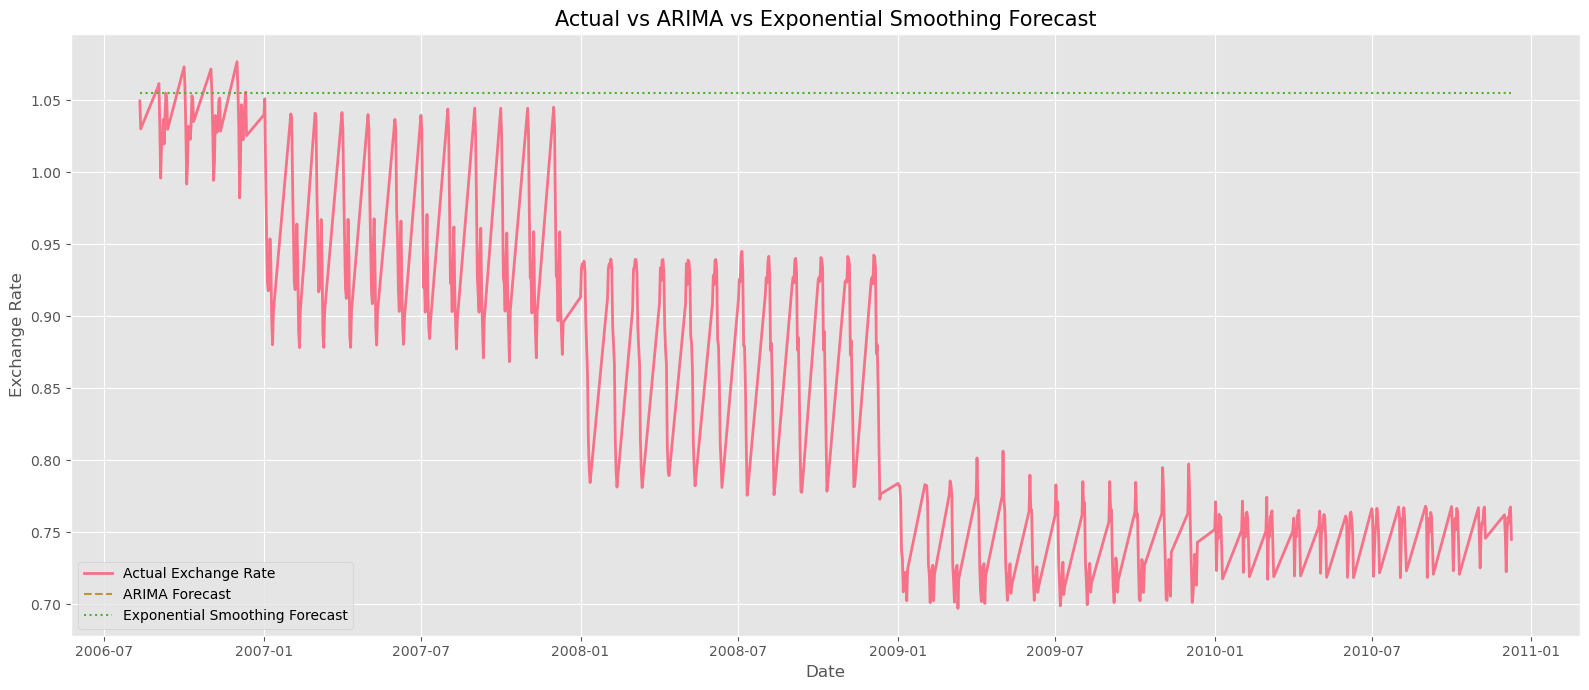

In [43]:
plt.figure(figsize=(16, 7))

# Actual values
plt.plot(
    test.index,
    test,
    label="Actual Exchange Rate",
    linewidth=2
)

# ARIMA forecast
plt.plot(
    test.index,
    arima_forecast,
    label="ARIMA Forecast",
    linestyle="--"
)

# Exponential Smoothing forecast
plt.plot(
    test.index,
    es_forecast,
    label="Exponential Smoothing Forecast",
    linestyle=":"
)

plt.title(
    "Actual vs ARIMA vs Exponential Smoothing Forecast",
    fontsize=15
)

plt.xlabel("Date")
plt.ylabel("Exchange Rate")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

30. Identify the Best Performing Model

In [44]:
# Determine the best model based on RMSE
best_model_name = comparison.loc[
    comparison["RMSE"].idxmin(),
    "Model"
]

print("Best Performing Model:", best_model_name)

print("\nModel Performance Summary:")
display(comparison.sort_values("RMSE"))

Best Performing Model: ARIMA

Model Performance Summary:


,Model,MAE,RMSE,MAPE (%)
0,ARIMA,0.1912,0.2191,24.5063
1,Exponential Smoothing,0.2067,0.2336,26.3853


Part 5: Future Exchange Rate Forecasting

31. Forecast Future Exchange Rates

In [45]:
# Define future forecast horizon
forecast_steps = 30

# Fit ARIMA using complete dataset
final_arima = ARIMA(
    series,
    order=best_order
).fit()

# Fit Exponential Smoothing using complete dataset
final_es = ExponentialSmoothing(
    series,
    trend="add",
    damped_trend=True,
    seasonal=None,
    initialization_method="estimated"
).fit()

# Generate future forecasts
future_arima = final_arima.forecast(
    steps=forecast_steps
)

future_es = final_es.forecast(
    steps=forecast_steps
)

# Determine the dataset frequency
frequency = pd.infer_freq(series.index)

# Fallback if frequency cannot be inferred
if frequency is None:
    frequency = pd.tseries.frequencies.to_offset(
        series.index.to_series().diff().median()
    )

# Generate future date index
future_dates = pd.date_range(
    start=series.index[-1],
    periods=forecast_steps + 1,
    freq=frequency
)[1:]

# Create future forecast DataFrame
future_forecast = pd.DataFrame({
    "ARIMA Forecast": np.asarray(future_arima),
    "Exponential Smoothing Forecast": np.asarray(future_es)
}, index=future_dates)

future_forecast.index.name = "Date"

# Display predictions
display(future_forecast.head(10))

,ARIMA Forecast,Exponential Smoothing Forecast
Date,,
2010-12-10,0.7429,0.7454
2010-12-11,0.7474,0.7454
2010-12-12,0.7503,0.7454
2010-12-13,0.7504,0.7454
2010-12-14,0.7514,0.7454
2010-12-15,0.7509,0.7454
2010-12-16,0.7516,0.7454
2010-12-17,0.7510,0.7454
2010-12-18,0.7516,0.7454


32. Visualize Future Predictions

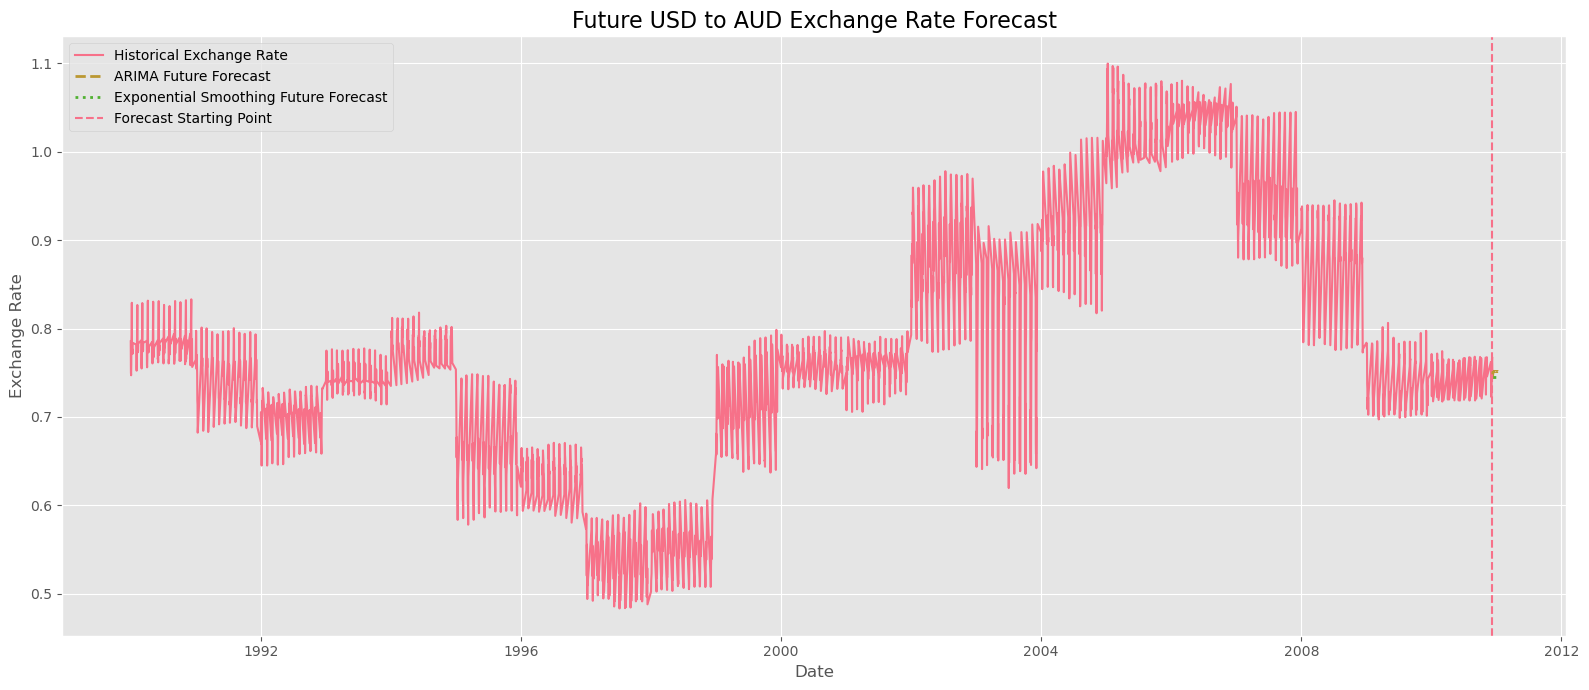

In [46]:
plt.figure(figsize=(16, 7))

# Historical observations
plt.plot(
    series.index,
    series,
    label="Historical Exchange Rate",
    linewidth=1.5
)

# ARIMA future forecast
plt.plot(
    future_forecast.index,
    future_forecast["ARIMA Forecast"],
    label="ARIMA Future Forecast",
    linestyle="--",
    linewidth=2
)

# Exponential Smoothing future forecast
plt.plot(
    future_forecast.index,
    future_forecast["Exponential Smoothing Forecast"],
    label="Exponential Smoothing Future Forecast",
    linestyle=":",
    linewidth=2
)

plt.axvline(
    x=series.index[-1],
    linestyle="--",
    label="Forecast Starting Point"
)

plt.title(
    "Future USD to AUD Exchange Rate Forecast",
    fontsize=16
)

plt.xlabel("Date")
plt.ylabel("Exchange Rate")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

33. Export Forecast Results to CSV

In [47]:
# Export future predictions
future_forecast.to_csv(
    "exchange_rate_future_forecast.csv"
)

print("Future forecast saved successfully!")

Future forecast saved successfully!


In [48]:
comparison.to_csv(
    "exchange_rate_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!
